# Service provision

`get_service_provision` allocates the demand of buildings to services with limited capacity, given a matrix of
travel costs and a normative threshold. This notebook

1. computes provision with a 10-minute threshold on a precomputed intermodal travel-time matrix;
2. maps the provision value and service load;
3. removes links longer than 8 minutes with `recalculate_links` and clips the result to a subarea;
4. repeats the calculation with a pandas sparse matrix.

The matrix in `examples_data/matrix_time.parquet` was computed with IduEdu
([calculate_od_matrix](calculate_od_matrix.ipynb)); unreachable pairs are `inf`.

The last section, *Your own area*, shows what to replace to get the same pictures for another territory.

In [1]:
# !pip install objectnat pyarrow matplotlib

In [2]:
import geopandas as gpd
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from objectnat import (
    clip_provision,
    get_provision_buildings,
    get_provision_links,
    get_provision_services,
    get_service_provision,
    recalculate_links,
)

buildings = gpd.read_parquet("examples_data/buildings.parquet")
services = gpd.read_parquet("examples_data/services.parquet")
matrix = pd.read_parquet("examples_data/matrix_time.parquet")  # minutes, rows: buildings, columns: services
print(f"{len(buildings)} buildings (demand {buildings['demand'].sum()}), "
      f"{len(services)} services (capacity {services['capacity'].sum()}), matrix {matrix.shape}")

4101 buildings (demand 29596), 36 services (capacity 31142), matrix (4101, 36)


## 1. Provision within 10 minutes

The result is a `ProvisionResult`: a sparse `flow` matrix of allocated demand and the tables `demand_rows` and
`capacity_rows`. A fixed `seed` makes the allocation reproducible.

In [3]:
result = get_service_provision(buildings=buildings, services=services, distance_matrix=matrix, threshold=10, seed=0)
# the result brings its own demand/capacity columns, so the input ones are dropped before joining
buildings_prov = get_provision_buildings(buildings.drop(columns="demand"), result)
services_prov = get_provision_services(services.drop(columns="capacity"), result)
links = get_provision_links(buildings, services, result)

demand = result.demand_rows
print(f"supplied within 10 min: {demand['supplied_demands_within'].sum() / demand['demand'].sum():.1%}, "
      f"beyond: {demand['supplied_demands_without'].sum() / demand['demand'].sum():.1%}, "
      f"left: {demand['demand_left'].sum() / demand['demand'].sum():.1%}")
result.capacity_rows.describe().round(1)

supplied within 10 min: 61.7%, beyond: 33.4%, left: 4.9%


,capacity,capacity_left,carried_capacity_within,carried_capacity_without,service_load
count,36.0,36.0,36.0,36.0,36.0
mean,865.1,83.3,507.0,274.7,781.8
std,487.1,110.6,319.9,320.0,434.1
min,120.0,0.0,61.0,2.0,100.0
25%,550.8,13.8,242.5,42.2,457.0
50%,960.0,36.0,493.0,185.0,805.5
75%,1200.0,113.0,725.2,398.0,1138.2
max,2161.0,457.0,1145.0,1402.0,1756.0


## 2. Maps

`provision_value` is the share of a building's demand supplied by services within the threshold; `service_load` is
the total demand allocated to a service.

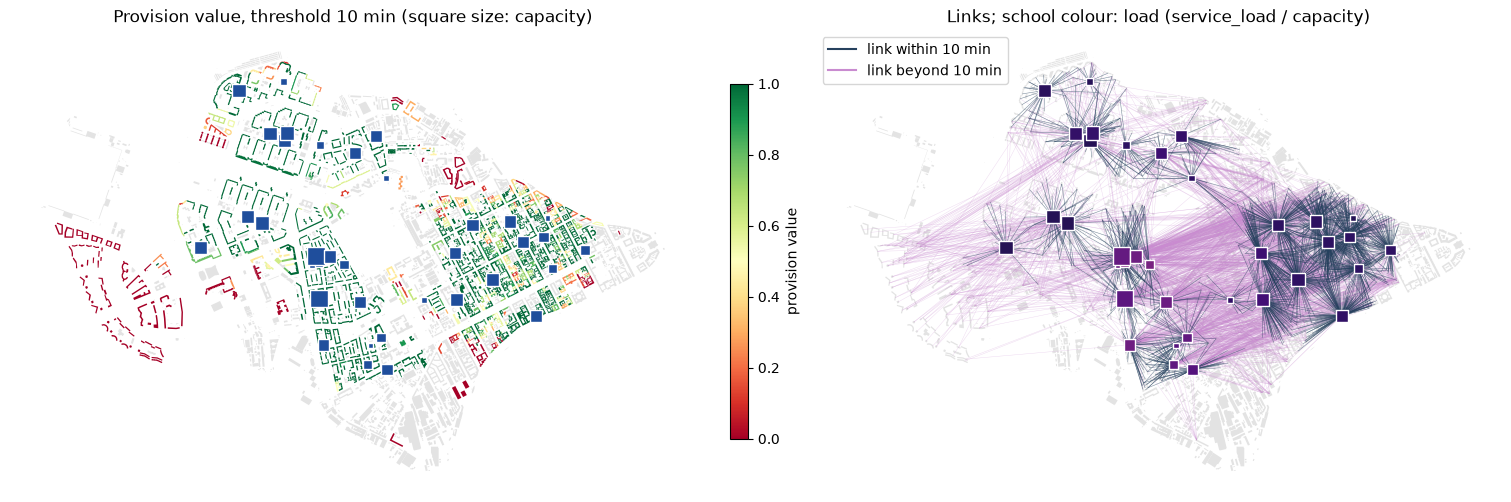

In [4]:
from matplotlib.lines import Line2D


def school_markers(ax, schools, color="#1f4e9c"):
    """Schools as filled squares sized by capacity."""
    schools.plot(ax=ax, marker="s", markersize=8 + 0.07 * schools["capacity"], color=color, edgecolor="white",
                 linewidth=1, zorder=5)


living = buildings_prov[buildings_prov["demand"] > 0]
fig, axs = plt.subplots(1, 2, figsize=(15, 6), constrained_layout=True)
ax = axs[0]
buildings_prov[buildings_prov["demand"] <= 0].plot(ax=ax, color="#e3e3e3", linewidth=0)
living.plot(ax=ax, column="provision_value", cmap="RdYlGn", vmin=0, vmax=1, legend=True,
            legend_kwds={"label": "provision value", "shrink": 0.6})
school_markers(ax, services_prov)
ax.set_title("Provision value, threshold 10 min (square size: capacity)")
ax = axs[1]
buildings.plot(ax=ax, color="#e3e3e3", linewidth=0)
within = links["distance"] <= 10
links[~within].plot(ax=ax, color="#c98bd0", linewidth=0.3, alpha=0.35)
links[within].plot(ax=ax, color="#26415e", linewidth=0.4, alpha=0.6)
load_share = (services_prov["service_load"] / services_prov["capacity"]).clip(0, 1)
school_markers(ax, services_prov, color=plt.get_cmap("magma_r")(0.15 + 0.7 * load_share))
ax.legend(handles=[Line2D([], [], color="#26415e", label="link within 10 min"),
                   Line2D([], [], color="#c98bd0", label="link beyond 10 min")], loc="upper left")
ax.set_title("Links; school colour: load (service_load / capacity)")
for ax in axs:
    ax.set_axis_off()
plt.show()

## 3. Shorter threshold and clipping

`recalculate_links` removes flows whose cost exceeds `new_max_dist` and rebuilds the metrics; removed demand is not
reallocated. `clip_provision` keeps buildings intersecting a zone, their links and the services they use.

In [5]:
result_8 = recalculate_links(result, new_max_dist=8)
removed = result.demand_rows["demand_left"].sum(), result_8.demand_rows["demand_left"].sum()
print(f"unsupplied demand: {removed[0]} with all links, {removed[1]} after removing links longer than 8 min")

buildings_8 = get_provision_buildings(buildings.drop(columns="demand"), result_8)
services_8 = get_provision_services(services.drop(columns="capacity"), result_8)
links_8 = get_provision_links(buildings, services, result_8)

zone = buildings.iloc[500:503][["geometry"]].copy()
zone["geometry"] = zone.buffer(500)
b_clip, s_clip, l_clip = clip_provision(buildings_8, services_8, links_8, selection_zone=zone)
print(len(b_clip), "buildings,", len(s_clip), "services,", len(l_clip), "links in the zone")

unsupplied demand: 1453 with all links, 13115 after removing links longer than 8 min
449 buildings, 15 services, 363 links in the zone


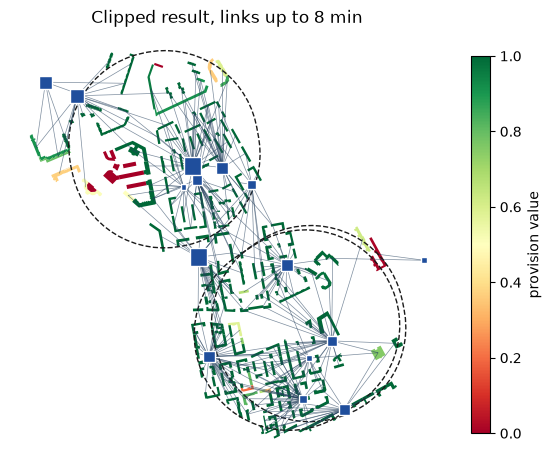

In [6]:
fig, ax = plt.subplots(figsize=(7, 7))
zone.boundary.plot(ax=ax, color="#1a1a1a", linewidth=1, linestyle="--")
b_clip[b_clip["demand"] > 0].plot(ax=ax, column="provision_value", cmap="RdYlGn", vmin=0, vmax=1, legend=True,
                                  legend_kwds={"label": "provision value", "shrink": 0.7})
l_clip.plot(ax=ax, color="#26415e", linewidth=0.5, alpha=0.6)
school_markers(ax, s_clip)
ax.set_title("Clipped result, links up to 8 min")
ax.set_axis_off()
plt.show()

## 4. Sparse matrices

For large areas most building–service pairs are unreachable within any reasonable cost. A pandas sparse DataFrame
with `NaN` (or `inf`) as fill value stores only reachable pairs; `get_service_provision` reads it entry by entry
without densifying. IduEdu's `od_matrix` returns such a matrix.

Only pairs with a cost up to `3 * threshold` take part in the allocation. For a 5-minute threshold the pairs beyond
15 minutes can therefore be dropped without changing the result:

In [7]:
sparse = matrix.where(matrix <= 15).astype(pd.SparseDtype("float64", np.nan))
print(f"dense: {matrix.memory_usage().sum() / 1e6:.2f} MB, sparse (pairs within 15 min): "
      f"{sparse.memory_usage().sum() / 1e6:.2f} MB, density {sparse.sparse.density:.1%}")

dense_5 = get_service_provision(buildings=buildings, services=services, distance_matrix=matrix, threshold=5, seed=0)
sparse_5 = get_service_provision(buildings=buildings, services=services, distance_matrix=sparse, threshold=5, seed=0)
allocation = ["demand_left", "supplied_demands_within", "supplied_demands_without", "avg_dist", "provision_value"]
same = dense_5.demand_rows[allocation].fillna(-1).equals(sparse_5.demand_rows[allocation].fillna(-1))
print("same allocation with the dense and the sparse matrix:", same)
# min_dist is read from the matrix itself: NaN where the nearest service is beyond the 15-minute cut
print("buildings whose nearest service is beyond 15 min:", int(sparse_5.demand_rows["min_dist"].isna().sum()))

dense: 1.03 MB, sparse (pairs within 15 min): 0.31 MB, density 17.4%
same allocation with the dense and the sparse matrix: True
buildings whose nearest service is beyond 15 min: 243


## 5. Your own area

Buildings with a demand column, services with a capacity column and the travel costs between them
([calculate_od_matrix](calculate_od_matrix.ipynb) builds the matrix for any area). The provision joins back to the
buildings: draw it with matplotlib, explore it on a web map or save it for GIS with `to_file`.

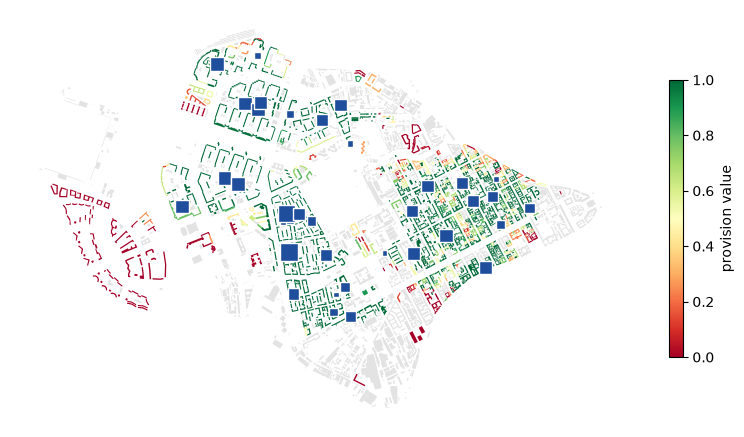

In [8]:
my_buildings, my_services, my_matrix = buildings, services, matrix  # matrix rows and columns: their indices

my_result = get_service_provision(
    buildings=my_buildings, services=my_services, distance_matrix=my_matrix, threshold=10, seed=0
)
my_prov = get_provision_buildings(my_buildings.drop(columns="demand"), my_result)
my_schools = get_provision_services(my_services.drop(columns="capacity"), my_result)

fig, ax = plt.subplots(figsize=(10, 6))
my_prov[my_prov["demand"] <= 0].plot(ax=ax, color="#e3e3e3", linewidth=0)
my_prov[my_prov["demand"] > 0].plot(ax=ax, column="provision_value", cmap="RdYlGn", vmin=0, vmax=1, legend=True,
                                    legend_kwds={"label": "provision value", "shrink": 0.6})
school_markers(ax, my_schools)
ax.set_axis_off()
plt.show()
# my_prov.to_file("my_provision.gpkg")  # for GIS

In [9]:
my_prov[my_prov["demand"] > 0].explore(column="provision_value", cmap="RdYlGn", vmin=0, vmax=1,
                                       tiles="CartoDB Positron")